# KNN with PCA: TMDB viewer rating
Predict `vote_average` from the existing feature-engineering CSV. KNN uses similar earlier movies: average their ratings for regression, or use their hit votes for classification. PCA compresses the encoded features before measuring similarity.

Pipeline: **impute → encode → standardize all inputs → PCA → KNN**. All learned steps are fitted again inside each chronological training fold. Current outcomes, IDs, and revenue are excluded. The existing CSVs are read-only.

Use the same **2017-11-18** outer cutoff as the other models. These are exploratory results on an already-inspected test period. Histories are retrospective and update through time.

References: [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [KNN](https://scikit-learn.org/stable/modules/neighbors).

## Tuning controls — edit here first
Change the next cell, save, then **Run All**.

| Control | What to change |
|---|---|
| `MODEL_SETTINGS` | Original neighbor count, weights, and distance (`p=2` is Euclidean). |
| `PCA_SETTINGS` | Original fraction of input variance retained, solver, and whitening. |
| `PARAM_GRID` | Trial `pca__n_components`, neighbor counts, and weights. Grid values override original settings. |
| `FEATURE_GROUPS_TO_COMPARE` | Inputs to compare; keep `All features` as the reference. |
| `CUTOFF_DATE`, `N_VALIDATION_SPLITS` | Keep consistent with the other models. |

PCA variance retained describes the **inputs**, not predictive R². Standardizing binary/category indicators gives rare categories more influence; validate this choice. PCA can discard useful signal and need not improve KNN. Distance-weighted KNN can fit training observations almost perfectly because each point is its own neighbor; validation/test results determine usefulness.

In [1]:
# EDIT THIS CELL, then save and Run All. Do not change settings in later cells.
DATA_FILE = "../../data/model_data_rating.csv"
CUTOFF_DATE = "2017-11-18"  # Change consistently across models for a fair comparison.
N_VALIDATION_SPLITS = 3     # Expanding chronological folds inside training.

# Fixed original-model settings. Grid values below override these during a search.
MODEL_SETTINGS = {"n_neighbors": 35, "weights": "uniform", "p": 2, "n_jobs": 2}
PCA_SETTINGS = {"n_components": 0.95, "svd_solver": "full", "whiten": False}

# CHANGE THESE LISTS to try model settings. More values mean a longer run.
# Tune PCA variance retained, neighbor count, and neighbor weighting together.
PARAM_GRID = {
    "pca__n_components": [0.80, 0.95],
    "regression__n_neighbors": [15, 35, 75],
    "regression__weights": ["uniform", "distance"],
}
TUNING_METRIC = "MAE"
# MAE/RMSE: lower is better. R2: higher is better.

# Remove a group to skip it; keep All features for the reference comparison.
FEATURE_GROUPS_TO_COMPARE = [
    "Movie characteristics", "+ Director history", "+ Actor history", "All features",
]
assert "All features" in FEATURE_GROUPS_TO_COMPARE

assert isinstance(N_VALIDATION_SPLITS, int) and N_VALIDATION_SPLITS >= 2

assert set(FEATURE_GROUPS_TO_COMPARE) <= {"Movie characteristics", "+ Director history", "+ Actor history", "All features"}


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

movies = pd.read_csv(DATA_FILE, parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
assert movies["tmdb_id"].is_unique
assert movies["release_date"].notna().all()
assert movies["vote_average"].notna().all() and movies["vote_average"].between(0, 10).all()
print(f"Loaded {len(movies):,} movies | Target: vote_average")

Loaded 13,276 movies | Target: vote_average


## 1. Select predictors
Exclude the current-movie outcome (`vote_average`) and movie identifiers from the inputs. Keep release year numeric and treat release month as categorical.

In [3]:
ID_COLUMNS = ["tmdb_id", "imdb_id", "title_tmdb", "release_date"]
TARGET_COLUMNS = ["vote_average"]
NUMERIC_FEATURES = [
    "runtime", "log_budget", "release_year", "n_genres", "imdb_director_count",
    "dir_prior_success_rate_smoothed", "dir_prior_rating_smoothed",
    "dir_prior_rated_films_log1p", "dir_prior_films_log1p",
    "dir_years_active_log1p", "dir_prior_known_films_log1p",
    "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    "franchise_prior_films_log1p",
]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = [
    "is_sequel", "is_english", "dir_first_film", "dir_no_track_record", "backfill_unavailable", "dir_no_rating_history",
] + [column for column in movies if column.startswith("genre_")]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))
assert set(movies) == set(ID_COLUMNS + TARGET_COLUMNS + FEATURE_COLUMNS)
assert not set(ID_COLUMNS + TARGET_COLUMNS) & set(FEATURE_COLUMNS)
assert not {"budget", "revenue", "revenue_to_budget", "popularity", "vote_count"} & set(FEATURE_COLUMNS)
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()

X = movies[FEATURE_COLUMNS].copy()
# String conversion is a fixed type conversion, not a learned transformation.
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies["vote_average"].copy()
print(f"Predictors: {len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical, {len(BINARY_FEATURES)} binary")

Predictors: 14 numeric, 2 categorical, 24 binary


## 2. Split by release date
Read `model_data_rating.csv`, built from the broader combined data without budget/revenue filters. Retain the previous experiment's fixed date cutoff **2017-11-18**: train before it and test on or after it. All movies sharing a date stay together. The expanded cohort has 9,405 training and 3,871 test movies (about 71/29, rather than the previous 80/20).

Training-only chronological folds are rebuilt within this expanded training set. Broader test-population scores are not directly comparable with earlier scores on only financially eligible movies. These data have already been inspected, so results remain exploratory.

In [4]:
cutoff = pd.Timestamp(CUTOFF_DATE)
train_mask = movies["release_date"].lt(cutoff)
test_mask = ~train_mask
X_train, X_test = X.loc[train_mask].copy(), X.loc[test_mask].copy()
y_train, y_test = y.loc[train_mask].copy(), y.loc[test_mask].copy()
assert len(X_train) > 0 and len(X_test) > 0
assert movies.loc[train_mask, "release_date"].max() < movies.loc[test_mask, "release_date"].min()
assert set(movies.loc[train_mask, "tmdb_id"]).isdisjoint(movies.loc[test_mask, "tmdb_id"])
display(pd.DataFrame([
    ["Training", int(train_mask.sum()), movies.loc[train_mask, "release_date"].min(), movies.loc[train_mask, "release_date"].max()],
    ["Test", int(test_mask.sum()), movies.loc[test_mask, "release_date"].min(), movies.loc[test_mask, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))

,Split,Movies,First release,Last release
0,Training,9405,1990-01-12,2017-11-17
1,Test,3871,2017-11-18,2025-12-28


## 3. Fit the original KNN + PCA pipeline
Impute numeric medians and categorical modes, encode all category levels, then standardize **numeric, binary, and encoded categorical inputs together**. PCA uses the training distribution only. Each fit creates fresh transformations. KNN then measures Euclidean distance in the retained component space.

In [5]:
def make_regression_model(columns):
    """Fresh preprocessing and regression for each feature set and split."""
    numeric = [column for column in NUMERIC_FEATURES if column in columns]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in BINARY_FEATURES if column in columns]
    assert set(numeric + categorical + binary) == set(columns)
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop=None, handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
        ("binary", "passthrough", binary),
    ])
    return Pipeline([
        ("preprocessor", preprocessing),
        ("scaler", StandardScaler()),
        ("pca", PCA(**PCA_SETTINGS)),
        ("regression", KNeighborsRegressor(**MODEL_SETTINGS)),
    ])

initial_model = make_regression_model(FEATURE_COLUMNS)
initial_model.fit(X_train, y_train)
initial_train_predictions = initial_model.predict(X_train)
initial_test_predictions = initial_model.predict(X_test)

baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_predictions = baseline.predict(np.zeros((len(y_test), 1)))
assert np.allclose(baseline_predictions, y_train.mean())
print(f"Training mean rating (baseline): {y_train.mean():.3f}")

Training mean rating (baseline): 6.399


## 4. Validate and tune KNN and PCA
Jointly try the top-cell variance fractions, neighbor counts, and weights using expanding chronological folds inside the training period. Every candidate refits imputation, encoding, scaling, and PCA. No later-test rows enter this search. The table reports validation means and variability.

In [6]:
from sklearn.model_selection import GridSearchCV

# Three expanding validation windows entirely within the outer training period.
tuning_dates = movies.loc[train_mask, "release_date"]
assert tuning_dates.index.equals(X_train.index)
unique_tuning_dates = np.sort(tuning_dates.unique())
tuning_splits = []
tuning_periods = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_tuning_dates), 1):
    fit_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[earlier]).to_numpy())
    validation_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[later]).to_numpy())
    assert tuning_dates.iloc[fit_positions].max() < tuning_dates.iloc[validation_positions].min()
    assert set(fit_positions).isdisjoint(validation_positions)
    tuning_splits.append((fit_positions, validation_positions))
    tuning_periods.append({
        "Fold": fold, "Training movies": len(fit_positions), "Validation movies": len(validation_positions),
        "Training ends": tuning_dates.iloc[fit_positions].max().date(),
        "Validation starts": tuning_dates.iloc[validation_positions].min().date(),
        "Validation ends": tuning_dates.iloc[validation_positions].max().date(),
    })
display(pd.DataFrame(tuning_periods))

SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

search = GridSearchCV(
    estimator=make_regression_model(FEATURE_COLUMNS), param_grid=PARAM_GRID,
    scoring=SCORING, refit=TUNING_METRIC, cv=tuning_splits,
    n_jobs=1, return_train_score=True, error_score="raise",
)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
tuning_results = pd.DataFrame({
    "Settings": cv_results["params"].map(lambda params: {key.split("__", 1)[1]: value for key, value in params.items()}),
})
for metric in SCORING:
    sign = -1 if metric in ["MAE", "RMSE"] else 1
    tuning_results["Training " + metric] = sign * cv_results["mean_train_" + metric]
    tuning_results["Validation " + metric] = sign * cv_results["mean_test_" + metric]
tuning_results["Validation score std"] = cv_results["std_test_" + TUNING_METRIC]
tuning_results = tuning_results.sort_values("Validation " + TUNING_METRIC, ascending=TUNING_METRIC in ["MAE", "RMSE"], kind="stable")
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    display(tuning_results.reset_index(drop=True).round(4))
print("Selection metric:", TUNING_METRIC)
print("Selected settings:", search.best_params_)
# GridSearchCV already refits the chosen pipeline on the full outer training period.
model = search.best_estimator_
assert set(FEATURE_COLUMNS).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
assert np.isfinite(test_predictions).all()

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,2099,2292,1999-10-08,1999-10-14,2006-10-06
1,2,4391,2417,2006-10-06,2006-10-07,2012-05-09
2,3,6808,2597,2012-05-09,2012-05-10,2017-11-17


,Settings,Training MAE,Validation MAE,Training RMSE,Validation RMSE,Training R2,Validation R2,Validation score std
0,"{'n_components': 0.95, 'n_neighbors': 35, 'weights': 'distance'}",0.0000,0.5556,0.0000,0.7137,1.0000,0.2148,0.0229
1,"{'n_components': 0.95, 'n_neighbors': 15, 'weights': 'distance'}",0.0000,0.5567,0.0000,0.7167,1.0000,0.2081,0.0236
2,"{'n_components': 0.95, 'n_neighbors': 35, 'weights': 'uniform'}",0.5349,0.5583,0.6825,0.7169,0.2667,0.2076,0.0228
3,"{'n_components': 0.95, 'n_neighbors': 15, 'weights': 'uniform'}",0.5168,0.5593,0.6595,0.7197,0.3151,0.2016,0.0234
4,"{'n_components': 0.95, 'n_neighbors': 75, 'weights': 'distance'}",0.0000,0.5604,0.0000,0.7182,1.0000,0.2050,0.0213
5,"{'n_components': 0.95, 'n_neighbors': 75, 'weights': 'uniform'}",0.5468,0.5631,0.6966,0.7214,0.2362,0.1979,0.0209
6,"{'n_components': 0.8, 'n_neighbors': 35, 'weights': 'distance'}",0.0000,0.5647,0.0000,0.7244,1.0000,0.1912,0.0209
7,"{'n_components': 0.8, 'n_neighbors': 15, 'weights': 'distance'}",0.0000,0.5652,0.0000,0.7259,1.0000,0.1875,0.0235
8,"{'n_components': 0.8, 'n_neighbors': 15, 'weights': 'uniform'}",0.5237,0.5680,0.6694,0.7296,0.2944,0.1792,0.0239
9,"{'n_components': 0.8, 'n_neighbors': 35, 'weights': 'uniform'}",0.5437,0.5687,0.6934,0.7290,0.2430,0.1809,0.0206


Selection metric: MAE
Selected settings: {'pca__n_components': 0.95, 'regression__n_neighbors': 35, 'regression__weights': 'distance'}


## 4b. Select features
Compare the four feature groups using both the initial settings and the settings selected above (skip duplicate configurations). Fit fresh preprocessing in each of the same three training-period chronological folds. This targets unnecessary predictors and tests whether the earlier settings search helps with a different feature group.

Choose by the existing `TUNING_METRIC` (MAE by default). OLS changes only its feature group; the remaining models can also use their previously selected settings.

Refit the chosen candidate on all outer training movies before evaluating later movies. **This is a second selection stage on already-used validation folds, not independent validation.** The original and settings-only models remain visible. The later test data is not used in this selection. Further iterations need a fresh evaluation period or nested chronological validation before a strong generalization claim.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings; do not redefine them here.**

In [7]:
# Preserve the previous settings-only model for an honest before/after comparison.
settings_model = model
settings_train_predictions = train_predictions.copy()
settings_test_predictions = test_predictions.copy()

movie_features = (
    ["runtime", "log_budget", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

improvement_configurations = {"Initial settings": {}}
initial_parameters = initial_model.get_params()
if any(initial_parameters[key] != value for key, value in search.best_params_.items()):
    improvement_configurations["Settings selected in 4"] = search.best_params_.copy()

# Store only out-of-fold scores. No test rows enter fitting or selection.
selection_rows = []
for setting_name, parameters in improvement_configurations.items():
    for feature_name, columns in feature_versions.items():
        for fold, (fit_positions, validation_positions) in enumerate(tuning_splits, 1):
            candidate = make_regression_model(columns).set_params(**parameters)
            candidate.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
            actual = y_train.iloc[validation_positions]
            predicted = candidate.predict(X_train.iloc[validation_positions])
            selection_rows.append({
                "Feature set": feature_name, "Settings": setting_name, "Fold": fold,
                "MAE": mean_absolute_error(actual, predicted),
                "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
                "R2": r2_score(actual, predicted),
            })
selection_metrics = ["MAE", "RMSE", "R2"]
selection_keys = ["Feature set", "Settings"]
selection_fold_results = pd.DataFrame(selection_rows)
assert selection_fold_results.groupby(selection_keys)["Fold"].nunique().eq(N_VALIDATION_SPLITS).all()
assert np.isfinite(selection_fold_results[selection_metrics].to_numpy()).all()
improvement_summary = selection_fold_results.groupby(selection_keys, sort=False).agg(
    **{metric: (metric, "mean") for metric in selection_metrics},
    Score_std=(TUNING_METRIC, "std"),
).reset_index()
improvement_summary = improvement_summary.sort_values(
    TUNING_METRIC, ascending=TUNING_METRIC in ["MAE", "RMSE"], kind="stable",
).reset_index(drop=True)
with pd.option_context("display.max_columns", None):
    display(improvement_summary.drop(columns=["Threshold distance"], errors="ignore").head(12).round(4))
winner = improvement_summary.iloc[0]
selected_feature_set = winner["Feature set"]
selected_feature_columns = feature_versions[selected_feature_set]
selected_parameters = improvement_configurations[winner["Settings"]]
print("Selected feature group:", selected_feature_set)
print("Selected parameter configuration:", winner["Settings"], selected_parameters)
print("Mean selection score (not independent validation):", round(float(winner[TUNING_METRIC]), 4))

model = make_regression_model(selected_feature_columns).set_params(**selected_parameters)
model.fit(X_train, y_train)
assert set(selected_feature_columns).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
assert np.isfinite(test_predictions).all()

,Feature set,Settings,MAE,RMSE,R2,Score_std
0,+ Actor history,Settings selected in 4,0.5545,0.7130,0.2162,0.0265
1,+ Director history,Settings selected in 4,0.5546,0.7126,0.2173,0.0251
2,All features,Settings selected in 4,0.5556,0.7137,0.2148,0.0281
3,Movie characteristics,Settings selected in 4,0.5575,0.7158,0.2103,0.0232
4,+ Actor history,Initial settings,0.5575,0.7163,0.2091,0.0262
5,+ Director history,Initial settings,0.5577,0.7160,0.2097,0.0246
6,All features,Initial settings,0.5583,0.7169,0.2076,0.0279
7,Movie characteristics,Initial settings,0.5620,0.7210,0.1990,0.0218


Selected feature group: + Actor history
Selected parameter configuration: Settings selected in 4 {'pca__n_components': 0.95, 'regression__n_neighbors': 35, 'regression__weights': 'distance'}
Mean selection score (not independent validation): 0.5545


## 5. Evaluate rating predictions
Compare KNN with PCA with always predicting the **training mean rating**.

- **MAE:** average absolute error in rating points; lower is better.
- **RMSE:** gives larger errors more weight; lower is better.
- **R²:** variation explained relative to predicting the evaluation sample's mean; higher is better and negative means worse than that reference.

Training scores help identify overfitting. The later test period has already been inspected during development, so these results are exploratory.

The table retains initial, settings-only, and feature-selected models. Plots and examples below use the feature-selected model.

In [8]:
def score_predictions(name, split, actual, predicted):
    return {
        "Model": name, "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }
results = pd.DataFrame([
    score_predictions("Training mean baseline", "Test", y_test, baseline_predictions),
    score_predictions("Initial KNN with PCA", "Training", y_train, initial_train_predictions),
    score_predictions("Initial KNN with PCA", "Test", y_test, initial_test_predictions),
    score_predictions("Settings-only KNN with PCA", "Training", y_train, settings_train_predictions),
    score_predictions("Settings-only KNN with PCA", "Test", y_test, settings_test_predictions),
    score_predictions("Feature-selected KNN with PCA", "Training", y_train, train_predictions),
    score_predictions("Feature-selected KNN with PCA", "Test", y_test, test_predictions),
])
display(results.round(4))
print("Predictions outside 0–10:", int(((test_predictions < 0) | (test_predictions > 10)).sum()))

,Model,Split,MAE,RMSE,R2
0,Training mean baseline,Test,0.6123,0.7746,-0.0734
1,Initial KNN with PCA,Training,0.5165,0.6629,0.3169
2,Initial KNN with PCA,Test,0.5386,0.6863,0.1574
3,Settings-only KNN with PCA,Training,0.0000,0.0000,1.0000
4,Settings-only KNN with PCA,Test,0.5375,0.6849,0.1608
5,Feature-selected KNN with PCA,Training,0.0000,0.0000,1.0000
6,Feature-selected KNN with PCA,Test,0.5371,0.6850,0.1606


Predictions outside 0–10: 0


## 6. Inspect prediction errors
The diagonal indicates perfect predictions. A positive residual (actual minus predicted) means underprediction. The table shows the first ten test movies in chronological order.

These outputs use the model selected in Section 4b.

/var/folders/s8/tp7sn0_52d556bhs1lz5lcs80000gn/T/ipykernel_25491/1426105967.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(prediction_examples.head(10).round(3))


,title_tmdb,release_date,vote_average,predicted_rating,residual
9405,Revenge,2017-11-18,6.500,6.088,0.412
9406,Darkest Hour,2017-11-22,7.400,7.003,0.397
9407,Le Brio,2017-11-22,7.000,6.367,0.633
9408,In the Fade,2017-11-23,6.898,6.608,0.290
9409,Forgotten,2017-11-29,7.900,6.546,1.354
9410,I Can Quit Whenever I Want 3: Ad Honorem,2017-11-30,7.300,6.042,1.258
9411,The Shape of Water,2017-12-01,7.200,6.799,0.401
9412,"Three Billboards Outside Ebbing, Missouri",2017-12-01,8.051,6.905,1.146
9413,Wonder Wheel,2017-12-01,6.400,6.779,-0.379
9414,Perfect Strangers,2017-12-01,6.684,6.781,-0.097


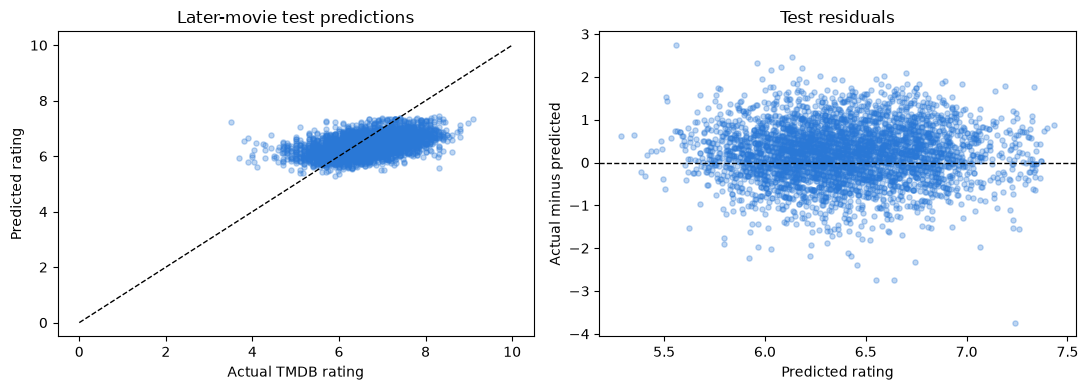

In [9]:
prediction_examples = movies.loc[test_mask, ["title_tmdb", "release_date", "vote_average"]].copy()
prediction_examples["predicted_rating"] = test_predictions
prediction_examples["residual"] = prediction_examples["vote_average"] - prediction_examples["predicted_rating"]
display(prediction_examples.head(10).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, test_predictions, alpha=0.3, s=14, color="#2a78d6")
axes[0].plot([0, 10], [0, 10], "k--", linewidth=1)
axes[0].set(xlabel="Actual TMDB rating", ylabel="Predicted rating", title="Later-movie test predictions")
axes[1].scatter(test_predictions, y_test.to_numpy() - test_predictions, alpha=0.3, s=14, color="#2a78d6")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Predicted rating", ylabel="Actual minus predicted", title="Test residuals")
plt.tight_layout()
plt.show()

## 7. Inspect PCA and compare against KNN without PCA
Show how many components remain and how much training input variance they retain. Compare fixed original KNN settings with and without PCA on identical training-validation folds. For success, this diagnostic uses the original 0.5 threshold; final precision/F1 selection is reported separately.

Selected input width: 54; retained components: 42
Retained training input variance: 95.499%
Selected settings: {'pca__n_components': 0.95, 'regression__n_neighbors': 35, 'regression__weights': 'distance'}


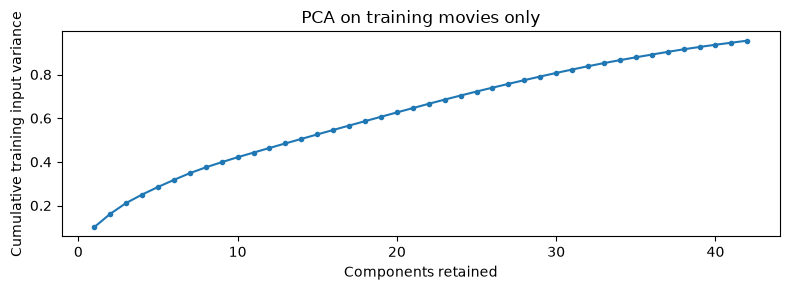

,MAE,RMSE,R2
Version,,,
KNN without PCA,0.5543,0.7117,0.2193
KNN with PCA,0.5583,0.7169,0.2076


This fixed-settings validation comparison isolates PCA; test results did not select either version.


In [10]:
from sklearn.base import clone
pca_step = model.named_steps["pca"]
encoded_width = model.named_steps["scaler"].n_features_in_
print(f"Selected input width: {encoded_width}; retained components: {pca_step.n_components_}")
print(f"Retained training input variance: {pca_step.explained_variance_ratio_.sum():.3%}")
print("Selected settings:", {key: model.get_params()[key] for key in PARAM_GRID})
assert pca_step.n_samples_ == len(y_train)
assert int(model.named_steps["scaler"].n_samples_seen_) == len(y_train)
assert set(selected_feature_columns).isdisjoint(ID_COLUMNS + TARGET_COLUMNS)
plt.figure(figsize=(8, 3))
plt.plot(np.arange(1, pca_step.n_components_ + 1), np.cumsum(pca_step.explained_variance_ratio_), marker=".")
plt.xlabel("Components retained")
plt.ylabel("Cumulative training input variance")
plt.title("PCA on training movies only")
plt.tight_layout()
plt.show()

# Original fixed KNN settings and all features: isolate PCA's effect using identical folds.
ablation_rows = []
for name in ["KNN without PCA", "KNN with PCA"]:
    for fold, (fit_positions, validation_positions) in enumerate(tuning_splits, 1):
        candidate = clone(initial_model)
        if name == "KNN without PCA":
            candidate.set_params(pca="passthrough")
        candidate.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
        actual = y_train.iloc[validation_positions]
        predicted = candidate.predict(X_train.iloc[validation_positions])
        metrics = {"MAE": mean_absolute_error(actual, predicted), "RMSE": np.sqrt(mean_squared_error(actual, predicted)), "R2": r2_score(actual, predicted)}
        ablation_rows.append({"Version": name, "Fold": fold, **metrics})
pca_ablation = pd.DataFrame(ablation_rows)
display(pca_ablation.groupby("Version", sort=False).mean(numeric_only=True).drop(columns="Fold").round(4))
assert len(pca_ablation) == 2 * N_VALIDATION_SPLITS
print("This fixed-settings validation comparison isolates PCA; test results did not select either version.")
# Provide the original all-feature folds to the shared visualization report.
feature_fold_results = selection_fold_results.loc[selection_fold_results["Settings"].eq("Initial settings") & selection_fold_results["Feature set"].eq("All features")].rename(columns={"Feature set": "Version"}).copy()


## Refresh the visualization report
This final cell saves metrics and prediction summaries for [the visualization notebook](../../Data_visualization/model_visualizations.ipynb). It does not write or modify dataset CSVs. Save this notebook before running all cells so report freshness checks match the code.

In [11]:
from pathlib import Path
import importlib.util

report_module_path = Path("../../Data_visualization/model_reports.py")
report_spec = importlib.util.spec_from_file_location("project_model_reports", report_module_path)
report_tools = importlib.util.module_from_spec(report_spec)
report_spec.loader.exec_module(report_tools)
report_path = report_tools.save_model_report(globals(), Path("knn_pca.ipynb"))
print("Visualization report saved:", report_path)

Visualization report saved: /Users/waltroou/DS-6021/DS_Final_Project/DS6021_Group2_FinalProject/Data_visualization/results/rating/knn_pca.json
